In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py
import re

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/refining/data_slash_results/"
filename = root + 'archs4_gene_human_v2.1_normalized_LW20230126.h5'
with h5py.File(filename, 'r') as f:
    low_cat_matrix = f['data/lowest_tier_category_matrix_qn'][:]
    high_cat_matrix = f['data/highest_tier_category_matrix_qn'][:] 
    gene_names = f['meta/genes/all_gene_names'][:]
    gene_description = f['meta/genes/gene_description'][:]
    category_names = f['meta/biosamples/category'][:]

category_names = [x.decode('UTF-8') for x in category_names]
gene_names = [x.decode('UTF-8') for x in gene_names]
gene_description = [x.decode('UTF-8') for x in gene_description]

category_list  = ["Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle","HUVEC", 
    "Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
    "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF",
    "HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
    "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
    "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
    "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus","Granulocyte", "Neutrophil", "Blymphocyte", 
    "Plasma Cell", "Plasmacytoid Dendritic Cell", 
    "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
    "Dendritic", "Kupffer", "Macrophage", "Macroglia",  "THP1", "U937", "JEG3", "Thymus", 
    "Thymocyte", "Spleen",
    "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
    "A431", "HACAT", "HNSCC","Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
    "Vascular Smooth Muscle", "LHCNM2","Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
    "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
    "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron","Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
    "Trachea","Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
    "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
    "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"]

category_dict  = {
    "Cardiovascular System" : ["Heart", "Atrium", "Cardiac Muscle Fiber", 
                               "Pericardium", "Valve", "Ventricle",
                               "HUVEC"], 
    
    "Connective Tissue" : ["Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
                           "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF"],

    "Digestive System": ["HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
                         "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
                         "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
                         "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus"],
    
    "Immune System" : ["Granulocyte", "Neutrophil", "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", 
                       "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
                       "Dendritic", "Kupffer", "Macrophage", "Macroglia",  "THP1", "U937", "JEG3", "Thymus", 
                       "Thymocyte", "Spleen"],
    
    "Integumentary System" : ["Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
                              "A431", "HACAT", "HNSCC"], 
    
    "Muscular System" : ["Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
                         "Vascular Smooth Muscle", "LHCNM2"], 
    
    "Nervous System" : ["Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
                        "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
                        "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron"], 
    
    "Respiratory System" : ["Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
                            "Trachea"], 
    
    "Urogenital System" : ["Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
                           "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
                           "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"]
}

In [8]:
category_dict = {
    "Cardiovascular System": {"Heart": [1, 2, 3], "Atrium": [4, 5, 6]},
    "Connective Tissue": {"Adipose": [7, 8, 9]}
}

system_dict = {}

for system, sub_dict in category_dict.items():
    temp_list = []
    for values_list in sub_dict.values():
        temp_list.extend(values_list)
    system_dict[system] = temp_list

print(system_dict)


{'Cardiovascular System': [1, 2, 3, 4, 5, 6], 'Connective Tissue': [7, 8, 9]}


In [10]:
import numpy as np

result_dict = {}

for category, values_list in system_dict.items():
    average = np.mean(values_list)
    divided_values = [value / average for value in values_list]
    result_dict[category] = divided_values

print(result_dict)


{'Cardiovascular System': [0.2857142857142857, 0.5714285714285714, 0.8571428571428571, 1.1428571428571428, 1.4285714285714286, 1.7142857142857142], 'Connective Tissue': [0.875, 1.0, 1.125]}


In [1]:
low_cat_matrix[0][0:3]

NameError: name 'low_cat_matrix' is not defined

In [4]:
high_cat_matrix[0][0:3]

array([0.03641399, 0.12006714, 0.4371865 ])

In [5]:
from IPython.display import display

df = pd.DataFrame(low_cat_matrix, index=gene_names)
df.columns = category_list
#display(df)

---
# Calculations

In [6]:

# Compute row-wise averages while skipping NaN values
row_averages = np.nanmean(low_cat_matrix, axis=1)

# Create new matrix where each value is divided by row average
low_cat_oe_matrix = np.divide(low_cat_matrix, row_averages[:, np.newaxis], 
                       out=np.zeros_like(low_cat_matrix), where=row_averages[:, np.newaxis]!=0)

print("Low Cat matrix shape:")
print(low_cat_matrix.shape)
print(low_cat_matrix[0][:5])
print()
print("Average:", row_averages[0])
print()
print("Low Cat OE matrix shape:")
print(low_cat_oe_matrix.shape)
print(low_cat_oe_matrix[0][:5])

Low Cat matrix shape:
(57447, 127)
[0.05616796 0.04883453        nan 0.02061483 0.03719162]

Average: 0.09820224169868699

Low Cat OE matrix shape:
(57447, 127)
[0.57196205 0.49728533        nan 0.20992223 0.37872471]


In [7]:
low_cat_log2_oe_matrix = np.log2(low_cat_oe_matrix)

In [8]:
from IPython.display import display

df = pd.DataFrame(low_cat_log2_oe_matrix, index=gene_names)
df.columns = category_list
#display(df)

---
# Save OE Matrix

In [9]:
# # Open the HDF5 file in read/write mode
# with h5py.File(filename, "a") as file:
#     # Access the "data" group
#     group = file["data"]
    
#     # Create and save the dataset
#     group.create_dataset("low_tier_oe_matrix_qn", data=low_cat_oe_matrix)
#     group.create_dataset("low_tier_log2oe_matrix_qn", data=low_cat_log2_oe_matrix)
    


---
# Results

In [33]:
# Low Category Matrix - Averages of Categories 

df = pd.DataFrame(low_cat_matrix, index=gene_names)
df.columns = category_list

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print()
    print('Gene descriptions for Column "{}":'.format(col))
    
    for gene in top_10.index:
        index = gene_names.index(gene)
        print(gene_description[index])
    print()


Top 10 values in Column "Heart":
TPM1               5.742830
TNNT2              5.338282
ACTC1              5.300183
AHNAK              5.196548
GAPDH              5.145582
RPL41              5.069228
TNNC1              4.838087
ENSG00000283907    4.796245
MYH7               4.612605
MYL2               4.601054
Name: Heart, dtype: float64

Gene descriptions for Column "Heart":
tropomyosin 1
troponin T2, cardiac type
actin alpha cardiac muscle 1
AHNAK nucleoprotein
glyceraldehyde-3-phosphate dehydrogenase
ribosomal protein L41
troponin C1, slow skeletal and cardiac type
novel transcript, antisense to ATP4A
myosin heavy chain 7
myosin light chain 2

Top 10 values in Column "Atrium":
NPPA      8.230254
MYL7      7.551266
ACTC1     6.878828
MYH6      6.852111
TNNT2     6.524649
TPM1      6.114578
MYL4      6.088424
DES       5.944048
ANKRD1    5.900489
CRYAB     5.670695
Name: Atrium, dtype: float64

Gene descriptions for Column "Atrium":
natriuretic peptide A
myosin light chain 7
actin al

Top 10 values in Column "Small Intestine":
RN7SL1             7.481959
RN7SL2             7.057652
AHNAK              5.908737
B2M                5.805965
SNORD3D            5.525371
ENSG00000283907    5.473805
RPL41              5.406175
TMSB4X             5.384495
EEF1A1             5.290359
RPS18              4.897919
Name: Small Intestine, dtype: float64

Gene descriptions for Column "Small Intestine":
RNA component of signal recognition particle 7SL1
RNA component of signal recognition particle 7SL2
AHNAK nucleoprotein
beta-2-microglobulin
small nucleolar RNA, C/D box 3D
novel transcript, antisense to ATP4A
ribosomal protein L41
thymosin beta 4 X-linked
eukaryotic translation elongation factor 1 alpha 1
ribosomal protein S18

Top 10 values in Column "Liver":
ALB                6.019595
FTL                6.013129
HP                 5.001778
RPL41              4.953933
SERPINA1           4.902178
ENSG00000283907    4.858437
APOA1              4.730877
APOA2              4.667427
FT

Top 10 values in Column "Alveolar":
FTL                7.357284
FTH1               6.589206
TMSB4X             6.088045
B2M                5.949586
AHNAK              5.144226
TMSB10             5.028673
ENSG00000283907    5.009946
EEF1A1             4.985978
RPL41              4.948868
ACTB               4.946105
Name: Alveolar, dtype: float64

Gene descriptions for Column "Alveolar":
ferritin light chain
ferritin heavy chain 1
thymosin beta 4 X-linked
beta-2-microglobulin
AHNAK nucleoprotein
thymosin beta 10
novel transcript, antisense to ATP4A
eukaryotic translation elongation factor 1 alpha 1
ribosomal protein L41
actin beta

Top 10 values in Column "Dendritic":
FTL        6.837067
TMSB4X     6.667645
B2M        6.179454
HLA-DRA    5.934298
FTH1       5.883748
CD74       5.827270
TMSB10     5.621153
ACTB       5.504899
RPL41      5.383096
AHNAK      5.238897
Name: Dendritic, dtype: float64

Gene descriptions for Column "Dendritic":
ferritin light chain
thymosin beta 4 X-linked
beta

Top 10 values in Column "Vascular Smooth Muscle":
GAPDH     6.441466
FTL       6.215082
COL1A1    6.074400
RPL41     5.999033
TMSB4X    5.927418
FTH1      5.860288
VIM       5.816866
AHNAK     5.767804
TMSB10    5.726166
COL1A2    5.722030
Name: Vascular Smooth Muscle, dtype: float64

Gene descriptions for Column "Vascular Smooth Muscle":
glyceraldehyde-3-phosphate dehydrogenase
ferritin light chain
collagen type I alpha 1 chain
ribosomal protein L41
thymosin beta 4 X-linked
ferritin heavy chain 1
vimentin
AHNAK nucleoprotein
thymosin beta 10
collagen type I alpha 2 chain

Top 10 values in Column "LHCNM2":
GAPDH     7.142394
FTH1      6.846385
TMSB10    6.546708
FTL       6.333931
AHNAK     6.312670
MT2A      6.290889
B2M       6.100877
S100A6    5.969637
VIM       5.926932
EEF1A1    5.783252
Name: LHCNM2, dtype: float64

Gene descriptions for Column "LHCNM2":
glyceraldehyde-3-phosphate dehydrogenase
ferritin heavy chain 1
thymosin beta 10
ferritin light chain
AHNAK nucleoprotein
metal

Top 10 values in Column "H1299":
GAPDH     7.544103
RPL41     6.773821
EEF1A1    6.695163
RPS18     6.004704
TMSB10    5.944571
RPS19     5.777851
RPS12     5.595477
RPS16     5.545075
RPL13     5.492190
RPL8      5.396575
Name: H1299, dtype: float64

Gene descriptions for Column "H1299":
glyceraldehyde-3-phosphate dehydrogenase
ribosomal protein L41
eukaryotic translation elongation factor 1 alpha 1
ribosomal protein S18
thymosin beta 10
ribosomal protein S19
ribosomal protein S12
ribosomal protein S16
ribosomal protein L13
ribosomal protein L8

Top 10 values in Column "IMR90":
GAPDH     6.765511
ACTB      6.253539
TMSB10    6.154713
FTL       5.927146
VIM       5.829569
LGALS1    5.815059
AHNAK     5.772658
TMSB4X    5.525071
ACTG1     5.474600
EEF1A1    5.469429
Name: IMR90, dtype: float64

Gene descriptions for Column "IMR90":
glyceraldehyde-3-phosphate dehydrogenase
actin beta
thymosin beta 10
ferritin light chain
vimentin
galectin 1
AHNAK nucleoprotein
thymosin beta 4 X-linked
ac

Top 10 values in Column "DU145":
GAPDH     7.078236
RPL41     6.715854
RPS18     6.501613
FTH1      6.177126
FTL       5.793427
S100A6    5.775132
AHNAK     5.622136
ENO1      5.559997
RPS2      5.508133
ACTB      5.499326
Name: DU145, dtype: float64

Gene descriptions for Column "DU145":
glyceraldehyde-3-phosphate dehydrogenase
ribosomal protein L41
ribosomal protein S18
ferritin heavy chain 1
ferritin light chain
S100 calcium binding protein A6
AHNAK nucleoprotein
enolase 1
ribosomal protein S2
actin beta

Top 10 values in Column "LNCAP":
RPL41     7.407375
RPS18     6.742820
RPS2      6.239265
GAPDH     6.095460
RPL13A    5.944676
RPL7A     5.892479
EEF1A1    5.771103
RPS24     5.600378
RPLP0     5.556416
RPL26     5.507384
Name: LNCAP, dtype: float64

Gene descriptions for Column "LNCAP":
ribosomal protein L41
ribosomal protein S18
ribosomal protein S2
glyceraldehyde-3-phosphate dehydrogenase
ribosomal protein L13a
ribosomal protein L7a
eukaryotic translation elongation factor 1 al

In [34]:
# Low Category Matrix - OE

df = pd.DataFrame(low_cat_oe_matrix, index=gene_names)
df.columns = category_list

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print()
    print('Gene descriptions for Column "{}":'.format(col))
    
    for gene in top_10.index:
        index = gene_names.index(gene)
        print(gene_description[index])
    print()


Top 10 values in Column "Heart":
RN7SKP288          60.015807
CACNA1C-IT1        59.236888
ENSG00000286639    49.689579
ENSG00000267784    49.565267
BTF3L4P4           45.925513
ENSG00000232056    45.245420
ENSG00000238156    43.591272
ENSG00000250500    42.585218
ENSG00000271401    37.209561
ENSG00000237324    36.547886
Name: Heart, dtype: float64

Gene descriptions for Column "Heart":
RN7SK pseudogene 288
CACNA1C intronic transcript 1
novel transcript
novel transcript, antisense to titin
basic transcription factor 3 like 4 pseudogene 4
novel transcript
novel transcript
eukaryotic translation initiation factor 2, subunit 3 gamma, 52kDa (EIF2S3) pseudogene
novel transcript
novel transcript

Top 10 values in Column "Atrium":
BMP10              92.512588
MIR208A            85.817873
ENSG00000287891    67.385660
MYBPHL             66.685877
ENSG00000261606    66.180544
ENSG00000225519    64.210066
LMAN1L             60.449920
MYH6               57.154627
LINC01880          54.779973
LINC0

Top 10 values in Column "Bone Marrow":
AHSP               39.896203
IGKV2-23           39.584173
LINC02573          39.177194
PRSS57             38.271208
RNA5SP394          35.898416
ENSG00000286151    32.188221
ENSG00000221031    31.954471
EPB42              31.721603
TRBVB              31.590087
MPO                30.448109
Name: Bone Marrow, dtype: float64

Gene descriptions for Column "Bone Marrow":
alpha hemoglobin stabilizing protein
immunoglobulin kappa variable 2-23 (pseudogene)
long intergenic non-protein coding RNA 2573
serine protease 57
RNA, 5S ribosomal pseudogene 394
SLAM family member 5-like pseudogene
None
erythrocyte membrane protein band 4.2
T cell receptor beta variable B (pseudogene)
myeloperoxidase

Top 10 values in Column "Chondrocyte":
CCN6               58.971136
EPYC               51.702784
ITIH6              50.054316
IBSP               48.459901
ACAN               46.527344
ENSG00000261257    45.796102
NOS2               44.930102
LINC02906          37.52740

Top 10 values in Column "Hepatic Stellate Cell":
ENSG00000284695    23.592698
MIR656             21.417322
SULT1E1            18.859414
MIR412             18.293262
MIR369             16.415354
MIR410             14.748502
MIR409             13.983665
MIR377             12.240145
ENSG00000228707    11.101532
COLEC11            10.900319
Name: Hepatic Stellate Cell, dtype: float64

Gene descriptions for Column "Hepatic Stellate Cell":
novel protein
microRNA 656
sulfotransferase family 1E member 1
microRNA 412
microRNA 369
microRNA 410
microRNA 409
microRNA 377
novel transcript
collectin subfamily member 11

Top 10 values in Column "Hepatocyte":
GAGE12C    48.815310
GAGE12D    48.815310
APCS       44.503269
HPX        39.852415
HAO1       38.711034
HABP2      38.706938
FGB        37.120937
ANGPTL3    36.711506
FGA        36.671618
LBP        36.518493
Name: Hepatocyte, dtype: float64

Gene descriptions for Column "Hepatocyte":
G antigen 12C
G antigen 12D
amyloid P component, serum
hemope

Top 10 values in Column "Plasma Cell":
IGHV3OR16-11    82.643455
IGHV3OR16-15    73.434339
IGHV3OR16-13    71.446504
IGHV3-60        71.398107
IGHV3-62        67.336964
IGHV3OR16-17    65.158567
IGLV3-17        65.129226
RNU6-1135P      65.022916
IGHV3-22        63.939817
IGHV3OR16-8     63.385570
Name: Plasma Cell, dtype: float64

Gene descriptions for Column "Plasma Cell":
immunoglobulin heavy variable 3/OR16-11 (pseudogene)
immunoglobulin heavy variable 3/OR16-15 (pseudogene)
immunoglobulin heavy variable 3/OR16-13 (non-functional)
immunoglobulin heavy variable 3-60 (pseudogene)
immunoglobulin heavy variable 3-62 (pseudogene)
immunoglobulin heavy variable 3/OR16-17 (non-functional)
immunoglobulin lambda variable 3-17 (pseudogene)
RNA, U6 small nuclear 1135, pseudogene
immunoglobulin heavy variable 3-22 (pseudogene)
immunoglobulin heavy variable 3/OR16-8 (non-functional)

Top 10 values in Column "Plasmacytoid Dendritic Cell":
A1BG        NaN
A1BG-AS1    NaN
A1CF        NaN
A2M       

Top 10 values in Column "Macrophage":
ACOD1              58.880479
ENSG00000225107    37.620318
CHIT1              30.397937
ADAMDEC1           29.455373
LINC01181          27.816142
ETV3L              27.277054
DCSTAMP            25.108518
GPR31              25.014187
ENSG00000270980    24.960766
LINC02244          24.752556
Name: Macrophage, dtype: float64

Gene descriptions for Column "Macrophage":
aconitate decarboxylase 1
novel transcript
chitinase 1
ADAM like decysin 1
long intergenic non-protein coding RNA 1181
ETS variant transcription factor 3 like
dendrocyte expressed seven transmembrane protein
G protein-coupled receptor 31
coiled-coil-helix-coiled-coil-helix domain containing 2 (CHCHD2) pseudogene
long intergenic non-protein coding RNA 2244

Top 10 values in Column "Macroglia":
A1BG        NaN
A1BG-AS1    NaN
A1CF        NaN
A2M         NaN
A2M-AS1     NaN
A2ML1       NaN
A2ML1-AS1   NaN
A2ML1-AS2   NaN
A2MP1       NaN
A3GALT2     NaN
Name: Macroglia, dtype: float64

Gene d

Top 10 values in Column "A431":
ENSG00000275877    44.969840
ENSG00000258665    36.637295
MAGEA4             32.674117
MAGEA4-AS1         32.269761
RNA5SP62           29.324734
RNA5SP444          28.532268
RNA5SP191          26.994446
ENSG00000283178    26.259083
RNA5SP215          25.990757
RNA5SP366          24.546285
Name: A431, dtype: float64

Gene descriptions for Column "A431":
5.8S ribosomal RNA
golgin A5 (GOLGA5) pseudogene
MAGE family member A4
MAGEA4 antisense RNA 1
RNA, 5S ribosomal pseudogene 62
RNA, 5S ribosomal pseudogene 444
RNA, 5S ribosomal pseudogene 191
chromosome X open reading frame 49 (CXorf49) pseudogene
RNA, 5S ribosomal pseudogene 215
RNA, 5S ribosomal pseudogene 366

Top 10 values in Column "HACAT":
ENSG00000255191    42.190827
ENSG00000225867    30.371138
SERPINB13          27.266316
MIR6510            25.752031
ENSG00000251508    24.589596
ENSG00000288108    24.379294
KRT13              23.990079
DSG4               22.896089
OR4C6              21.565680
SCGB

Top 10 values in Column "Motor Neuron":
HOXB1              62.798877
SLC5A7             52.797012
LINC01201          41.754867
ENSG00000265174    36.413822
SLC18A3            36.359174
LHX3               33.107685
ENSG00000253832    29.362263
NUTM2F             28.359841
ENSG00000277704    26.984006
ENSG00000261675    26.854425
Name: Motor Neuron, dtype: float64

Gene descriptions for Column "Motor Neuron":
homeobox B1
solute carrier family 5 member 7
long intergenic non-protein coding RNA 1201
novel transcript
solute carrier family 18 member A3
LIM homeobox 3
novel transcript
NUT family member 2F
chromosome 2 open reading frame 27B (C2orf27B) pseudogene
novel transcript

Top 10 values in Column "Sensory Neuron":
DRGX               82.194997
LINC02735          76.616945
MRGPRE             73.577709
PIRT               70.646086
ENSG00000232529    70.540363
CHRNB3             58.748861
SKOR2              50.937331
PRPH               47.440192
KIRREL3-AS3        47.230186
P2RX3           

Top 10 values in Column "FLPIN TREX 293":
LINC02226    53.443976
MIR17        46.218173
MIR18A       46.134449
MIR125B2     44.067903
MIR20A       42.918135
RNU5E-5P     39.297972
MIR504       35.989752
RNA5SP112    34.699153
MIR421       33.718358
MIR125A      33.100905
Name: FLPIN TREX 293, dtype: float64

Gene descriptions for Column "FLPIN TREX 293":
long intergenic non-protein coding RNA 2226
microRNA 17
microRNA 18a
microRNA 125b-2
microRNA 20a
RNA, U5E small nuclear 5, pseudogene
microRNA 504
RNA, 5S ribosomal pseudogene 112
microRNA 421
microRNA 125a

Top 10 values in Column "HEK293":
IRS4               24.804950
HOXD13             20.609857
IRS4-AS1           16.520050
LINC02226          15.992621
KRTAP19-1          13.084945
HOXD11             12.542814
MTCO2P25           12.405985
RNU1-83P           11.822039
HOXD10             11.814351
ENSG00000278039    11.533055
Name: HEK293, dtype: float64

Gene descriptions for Column "HEK293":
insulin receptor substrate 4
homeobox D13

In [37]:
# Low Category Matrix - Log2(OE)

df = pd.DataFrame(low_cat_log2_oe_matrix, index=gene_names)
df.columns = category_list

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 genes in Column "{}":'.format(col))
    for gene in top_10.index:
        index = gene_names.index(gene)
        value = top_10[gene]
        description = gene_description[index]
        print('{} ({}) [{}]'.format(gene,format(value, ".3f"), description))
    print()



Top 10 genes in Column "Heart":
RN7SKP288 (5.907) [RN7SK pseudogene 288]
CACNA1C-IT1 (5.888) [CACNA1C intronic transcript 1]
ENSG00000286639 (5.635) [novel transcript]
ENSG00000267784 (5.631) [novel transcript, antisense to titin]
BTF3L4P4 (5.521) [basic transcription factor 3 like 4 pseudogene 4]
ENSG00000232056 (5.500) [novel transcript]
ENSG00000238156 (5.446) [novel transcript]
ENSG00000250500 (5.412) [eukaryotic translation initiation factor 2, subunit 3 gamma, 52kDa (EIF2S3) pseudogene]
ENSG00000271401 (5.218) [novel transcript]
ENSG00000237324 (5.192) [novel transcript]

Top 10 genes in Column "Atrium":
BMP10 (6.532) [bone morphogenetic protein 10]
MIR208A (6.423) [microRNA 208a]
ENSG00000287891 (6.074) [novel transcript]
MYBPHL (6.059) [myosin binding protein H like]
ENSG00000261606 (6.048) [novel transcript]
ENSG00000225519 (6.005) [novel transcript]
LMAN1L (5.918) [lectin, mannose binding 1 like]
MYH6 (5.837) [myosin heavy chain 6]
LINC01880 (5.776) [long intergenic non-prote

Top 10 genes in Column "Hepatocyte":
GAGE12C (5.609) [G antigen 12C]
GAGE12D (5.609) [G antigen 12D]
APCS (5.476) [amyloid P component, serum]
HPX (5.317) [hemopexin]
HAO1 (5.275) [hydroxyacid oxidase 1]
HABP2 (5.275) [hyaluronan binding protein 2]
FGB (5.214) [fibrinogen beta chain]
ANGPTL3 (5.198) [angiopoietin like 3]
FGA (5.197) [fibrinogen alpha chain]
LBP (5.191) [lipopolysaccharide binding protein]

Top 10 genes in Column "Primary Liver Cell":
A1BG (nan) [alpha-1-B glycoprotein]
A1BG-AS1 (nan) [A1BG antisense RNA 1]
A1CF (nan) [APOBEC1 complementation factor]
A2M (nan) [alpha-2-macroglobulin]
A2M-AS1 (nan) [A2M antisense RNA 1]
A2ML1 (nan) [alpha-2-macroglobulin like 1]
A2ML1-AS1 (nan) [A2ML1 antisense RNA 1]
A2ML1-AS2 (nan) [A2ML1 antisense RNA 2]
A2MP1 (nan) [alpha-2-macroglobulin pseudogene 1]
A3GALT2 (nan) [alpha 1,3-galactosyltransferase 2]

Top 10 genes in Column "HEPG2":
ENSG00000230952 (6.504) [novel transcript]
BPIFB2 (6.414) [BPI fold containing family B member 2]
ENSG

Top 10 genes in Column "U937":
LINC02470 (6.181) [long intergenic non-protein coding RNA 2470]
CLEC2A (5.782) [C-type lectin domain family 2 member A]
HMGB1P22 (5.693) [high mobility group box 1 pseudogene 22]
ENSG00000285254 (5.516) [novel pseudogene]
SIGLEC12 (5.441) [sialic acid binding Ig like lectin 12]
TPSAB1 (5.392) [tryptase alpha/beta 1]
ENSG00000285722 (5.378) [novel transcript]
ENSG00000231912 (5.259) [novel transcript]
ENSG00000225365 (5.257) [novel transcript]
BARX1-DT (5.251) [BARX1 divergent transcript]

Top 10 genes in Column "JEG3":
GPR32 (6.675) [G protein-coupled receptor 32]
LGALS16 (6.564) [galectin 16]
RBMY1J (6.338) [RNA binding motif protein Y-linked family 1 member J]
CGB5 (6.174) [chorionic gonadotropin subunit beta 5]
MAGEA8 (6.166) [MAGE family member A8]
RBMY1B (6.155) [RNA binding motif protein Y-linked family 1 member B]
XAGE2 (6.145) [X antigen family member 2]
CGB3 (6.125) [chorionic gonadotropin subunit beta 3]
ERVV-1 (5.965) [endogenous retrovirus gro

Top 10 genes in Column "Cerebellum":
GABRA6 (6.624) [gamma-aminobutyric acid type A receptor subunit alpha6]
MIR4705 (6.608) [microRNA 4705]
RPL39P29 (6.599) [ribosomal protein L39 pseudogene 29]
MTND1P19 (6.566) [MT-ND1 pseudogene 19]
MIR2681 (6.552) [microRNA 2681]
ENSG00000248627 (6.512) [novel transcript]
ENSG00000250092 (6.457) [novel transcript]
ZNF385D-AS2 (6.457) [ZNF385D antisense RNA 2]
ENSG00000248766 (6.448) [novel pseudogene]
LIPT1P1 (6.432) [lipoyltransferase 1 pseudogene 1]

Top 10 genes in Column "Cerebral Cortex":
SLCO1C1 (5.829) [solute carrier organic anion transporter family member 1C1]
SLC1A2-AS1 (5.772) [SLC1A2 antisense RNA 1]
ENSG00000255542 (5.686) [novel transcript]
HEPN1 (5.675) [hepatocellular carcinoma, down-regulated 1]
SLC39A12 (5.608) [solute carrier family 39 member 12]
GRM3 (5.381) [glutamate metabotropic receptor 3]
MMD2 (5.239) [monocyte to macrophage differentiation associated 2]
ENSG00000248725 (5.232) [novel pseudogene]
ENSG00000248249 (5.186) [Ra

Top 10 genes in Column "MCF10":
ENSG00000287902 (4.859) [novel transcript]
SYT8 (4.822) [synaptotagmin 8]
SCNN1G (4.457) [sodium channel epithelial 1 subunit gamma]
LONRF2P4 (4.442) [LONRF2 pseudogene 4]
MIR4680 (4.357) [microRNA 4680]
ROS1 (4.281) [ROS proto-oncogene 1, receptor tyrosine kinase]
ENSG00000227292 (4.229) [novel transcript]
EPGN (4.122) [epithelial mitogen]
NANOGP9 (4.097) [Nanog homeobox pseudogene 9]
CCAT2 (4.095) [colon cancer associated transcript 2]

Top 10 genes in Column "MDAMB231":
CST4 (5.419) [cystatin S]
CST1 (4.553) [cystatin SN]
SPANXB1 (4.507) [SPANX family member B1]
ENSG00000260761 (4.501) [novel transcript]
ENSG00000287484 (3.944) [novel transcript]
KISS1 (3.930) [KiSS-1 metastasis suppressor]
SPANXA2 (3.922) [SPANX family member A2]
DUX4L33 (3.874) [double homeobox 4 like 33 (pseudogene)]
LINC01929 (3.861) [long intergenic non-protein coding RNA 1929]
ADGRD1-AS1 (3.856) [ADGRD1 antisense RNA 1]

Top 10 genes in Column "MDAMB468":
RNU6-1125P (5.712) [RNA

In [36]:
low_cat_abs_log2_oe_matrix = abs(np.log2(low_cat_oe_matrix))
abs_low_df = pd.DataFrame(low_cat_abs_log2_oe_matrix, index=gene_names)
abs_low_df.columns = category_list

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 genes in Column "{}":'.format(col))
    for gene in top_10.index:
        index = gene_names.index(gene)
        value = top_10[gene]
        description = gene_description[index]
        print('{} ({}) [{}]'.format(gene,format(value, ".3f"), description))
    print()


Top 10 genes in Column "Heart":
RN7SKP288 (5.907) [RN7SK pseudogene 288]
CACNA1C-IT1 (5.888) [CACNA1C intronic transcript 1]
ENSG00000286639 (5.635) [novel transcript]
ENSG00000267784 (5.631) [novel transcript, antisense to titin]
BTF3L4P4 (5.521) [basic transcription factor 3 like 4 pseudogene 4]
ENSG00000232056 (5.500) [novel transcript]
ENSG00000238156 (5.446) [novel transcript]
ENSG00000250500 (5.412) [eukaryotic translation initiation factor 2, subunit 3 gamma, 52kDa (EIF2S3) pseudogene]
ENSG00000271401 (5.218) [novel transcript]
ENSG00000237324 (5.192) [novel transcript]

Top 10 genes in Column "Atrium":
BMP10 (6.532) [bone morphogenetic protein 10]
MIR208A (6.423) [microRNA 208a]
ENSG00000287891 (6.074) [novel transcript]
MYBPHL (6.059) [myosin binding protein H like]
ENSG00000261606 (6.048) [novel transcript]
ENSG00000225519 (6.005) [novel transcript]
LMAN1L (5.918) [lectin, mannose binding 1 like]
MYH6 (5.837) [myosin heavy chain 6]
LINC01880 (5.776) [long intergenic non-prote

Top 10 genes in Column "Hepatocyte":
GAGE12C (5.609) [G antigen 12C]
GAGE12D (5.609) [G antigen 12D]
APCS (5.476) [amyloid P component, serum]
HPX (5.317) [hemopexin]
HAO1 (5.275) [hydroxyacid oxidase 1]
HABP2 (5.275) [hyaluronan binding protein 2]
FGB (5.214) [fibrinogen beta chain]
ANGPTL3 (5.198) [angiopoietin like 3]
FGA (5.197) [fibrinogen alpha chain]
LBP (5.191) [lipopolysaccharide binding protein]

Top 10 genes in Column "Primary Liver Cell":
A1BG (nan) [alpha-1-B glycoprotein]
A1BG-AS1 (nan) [A1BG antisense RNA 1]
A1CF (nan) [APOBEC1 complementation factor]
A2M (nan) [alpha-2-macroglobulin]
A2M-AS1 (nan) [A2M antisense RNA 1]
A2ML1 (nan) [alpha-2-macroglobulin like 1]
A2ML1-AS1 (nan) [A2ML1 antisense RNA 1]
A2ML1-AS2 (nan) [A2ML1 antisense RNA 2]
A2MP1 (nan) [alpha-2-macroglobulin pseudogene 1]
A3GALT2 (nan) [alpha 1,3-galactosyltransferase 2]

Top 10 genes in Column "HEPG2":
ENSG00000230952 (6.504) [novel transcript]
BPIFB2 (6.414) [BPI fold containing family B member 2]
ENSG

Top 10 genes in Column "U937":
LINC02470 (6.181) [long intergenic non-protein coding RNA 2470]
CLEC2A (5.782) [C-type lectin domain family 2 member A]
HMGB1P22 (5.693) [high mobility group box 1 pseudogene 22]
ENSG00000285254 (5.516) [novel pseudogene]
SIGLEC12 (5.441) [sialic acid binding Ig like lectin 12]
TPSAB1 (5.392) [tryptase alpha/beta 1]
ENSG00000285722 (5.378) [novel transcript]
ENSG00000231912 (5.259) [novel transcript]
ENSG00000225365 (5.257) [novel transcript]
BARX1-DT (5.251) [BARX1 divergent transcript]

Top 10 genes in Column "JEG3":
GPR32 (6.675) [G protein-coupled receptor 32]
LGALS16 (6.564) [galectin 16]
RBMY1J (6.338) [RNA binding motif protein Y-linked family 1 member J]
CGB5 (6.174) [chorionic gonadotropin subunit beta 5]
MAGEA8 (6.166) [MAGE family member A8]
RBMY1B (6.155) [RNA binding motif protein Y-linked family 1 member B]
XAGE2 (6.145) [X antigen family member 2]
CGB3 (6.125) [chorionic gonadotropin subunit beta 3]
ERVV-1 (5.965) [endogenous retrovirus gro

Top 10 genes in Column "Cerebellum":
GABRA6 (6.624) [gamma-aminobutyric acid type A receptor subunit alpha6]
MIR4705 (6.608) [microRNA 4705]
RPL39P29 (6.599) [ribosomal protein L39 pseudogene 29]
MTND1P19 (6.566) [MT-ND1 pseudogene 19]
MIR2681 (6.552) [microRNA 2681]
ENSG00000248627 (6.512) [novel transcript]
ENSG00000250092 (6.457) [novel transcript]
ZNF385D-AS2 (6.457) [ZNF385D antisense RNA 2]
ENSG00000248766 (6.448) [novel pseudogene]
LIPT1P1 (6.432) [lipoyltransferase 1 pseudogene 1]

Top 10 genes in Column "Cerebral Cortex":
SLCO1C1 (5.829) [solute carrier organic anion transporter family member 1C1]
SLC1A2-AS1 (5.772) [SLC1A2 antisense RNA 1]
ENSG00000255542 (5.686) [novel transcript]
HEPN1 (5.675) [hepatocellular carcinoma, down-regulated 1]
SLC39A12 (5.608) [solute carrier family 39 member 12]
GRM3 (5.381) [glutamate metabotropic receptor 3]
MMD2 (5.239) [monocyte to macrophage differentiation associated 2]
ENSG00000248725 (5.232) [novel pseudogene]
ENSG00000248249 (5.186) [Ra

Top 10 genes in Column "MCF10":
ENSG00000287902 (4.859) [novel transcript]
SYT8 (4.822) [synaptotagmin 8]
SCNN1G (4.457) [sodium channel epithelial 1 subunit gamma]
LONRF2P4 (4.442) [LONRF2 pseudogene 4]
MIR4680 (4.357) [microRNA 4680]
ROS1 (4.281) [ROS proto-oncogene 1, receptor tyrosine kinase]
ENSG00000227292 (4.229) [novel transcript]
EPGN (4.122) [epithelial mitogen]
NANOGP9 (4.097) [Nanog homeobox pseudogene 9]
CCAT2 (4.095) [colon cancer associated transcript 2]

Top 10 genes in Column "MDAMB231":
CST4 (5.419) [cystatin S]
CST1 (4.553) [cystatin SN]
SPANXB1 (4.507) [SPANX family member B1]
ENSG00000260761 (4.501) [novel transcript]
ENSG00000287484 (3.944) [novel transcript]
KISS1 (3.930) [KiSS-1 metastasis suppressor]
SPANXA2 (3.922) [SPANX family member A2]
DUX4L33 (3.874) [double homeobox 4 like 33 (pseudogene)]
LINC01929 (3.861) [long intergenic non-protein coding RNA 1929]
ADGRD1-AS1 (3.856) [ADGRD1 antisense RNA 1]

Top 10 genes in Column "MDAMB468":
RNU6-1125P (5.712) [RNA

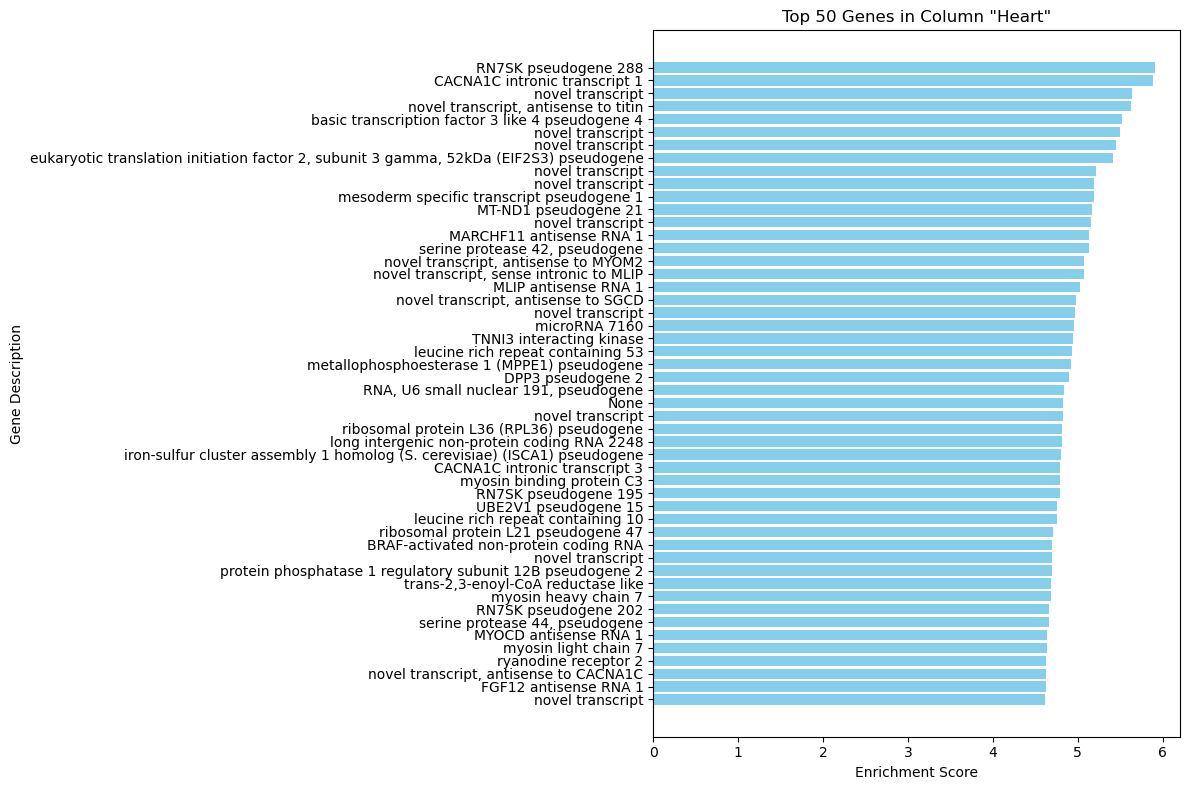

In [12]:
import matplotlib.pyplot as plt

# Select the column for the bar plot
column_name = "Heart"

# Get the top 50 scores for the selected column
top_50 = df[column_name].nlargest(50)
genes = [gene_names.index(gene) for gene in top_50.index]
scores = top_50.values

plt.figure(figsize=(12, 8))
plt.barh(range(len(genes)), scores, align='center', color='skyblue')
plt.yticks(range(len(genes)), [gene_description[gene] for gene in genes])
plt.xlabel('Enrichment Score')
plt.ylabel('Gene Description')
plt.title('Top 50 Genes in Column "{}"'.format(column_name))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

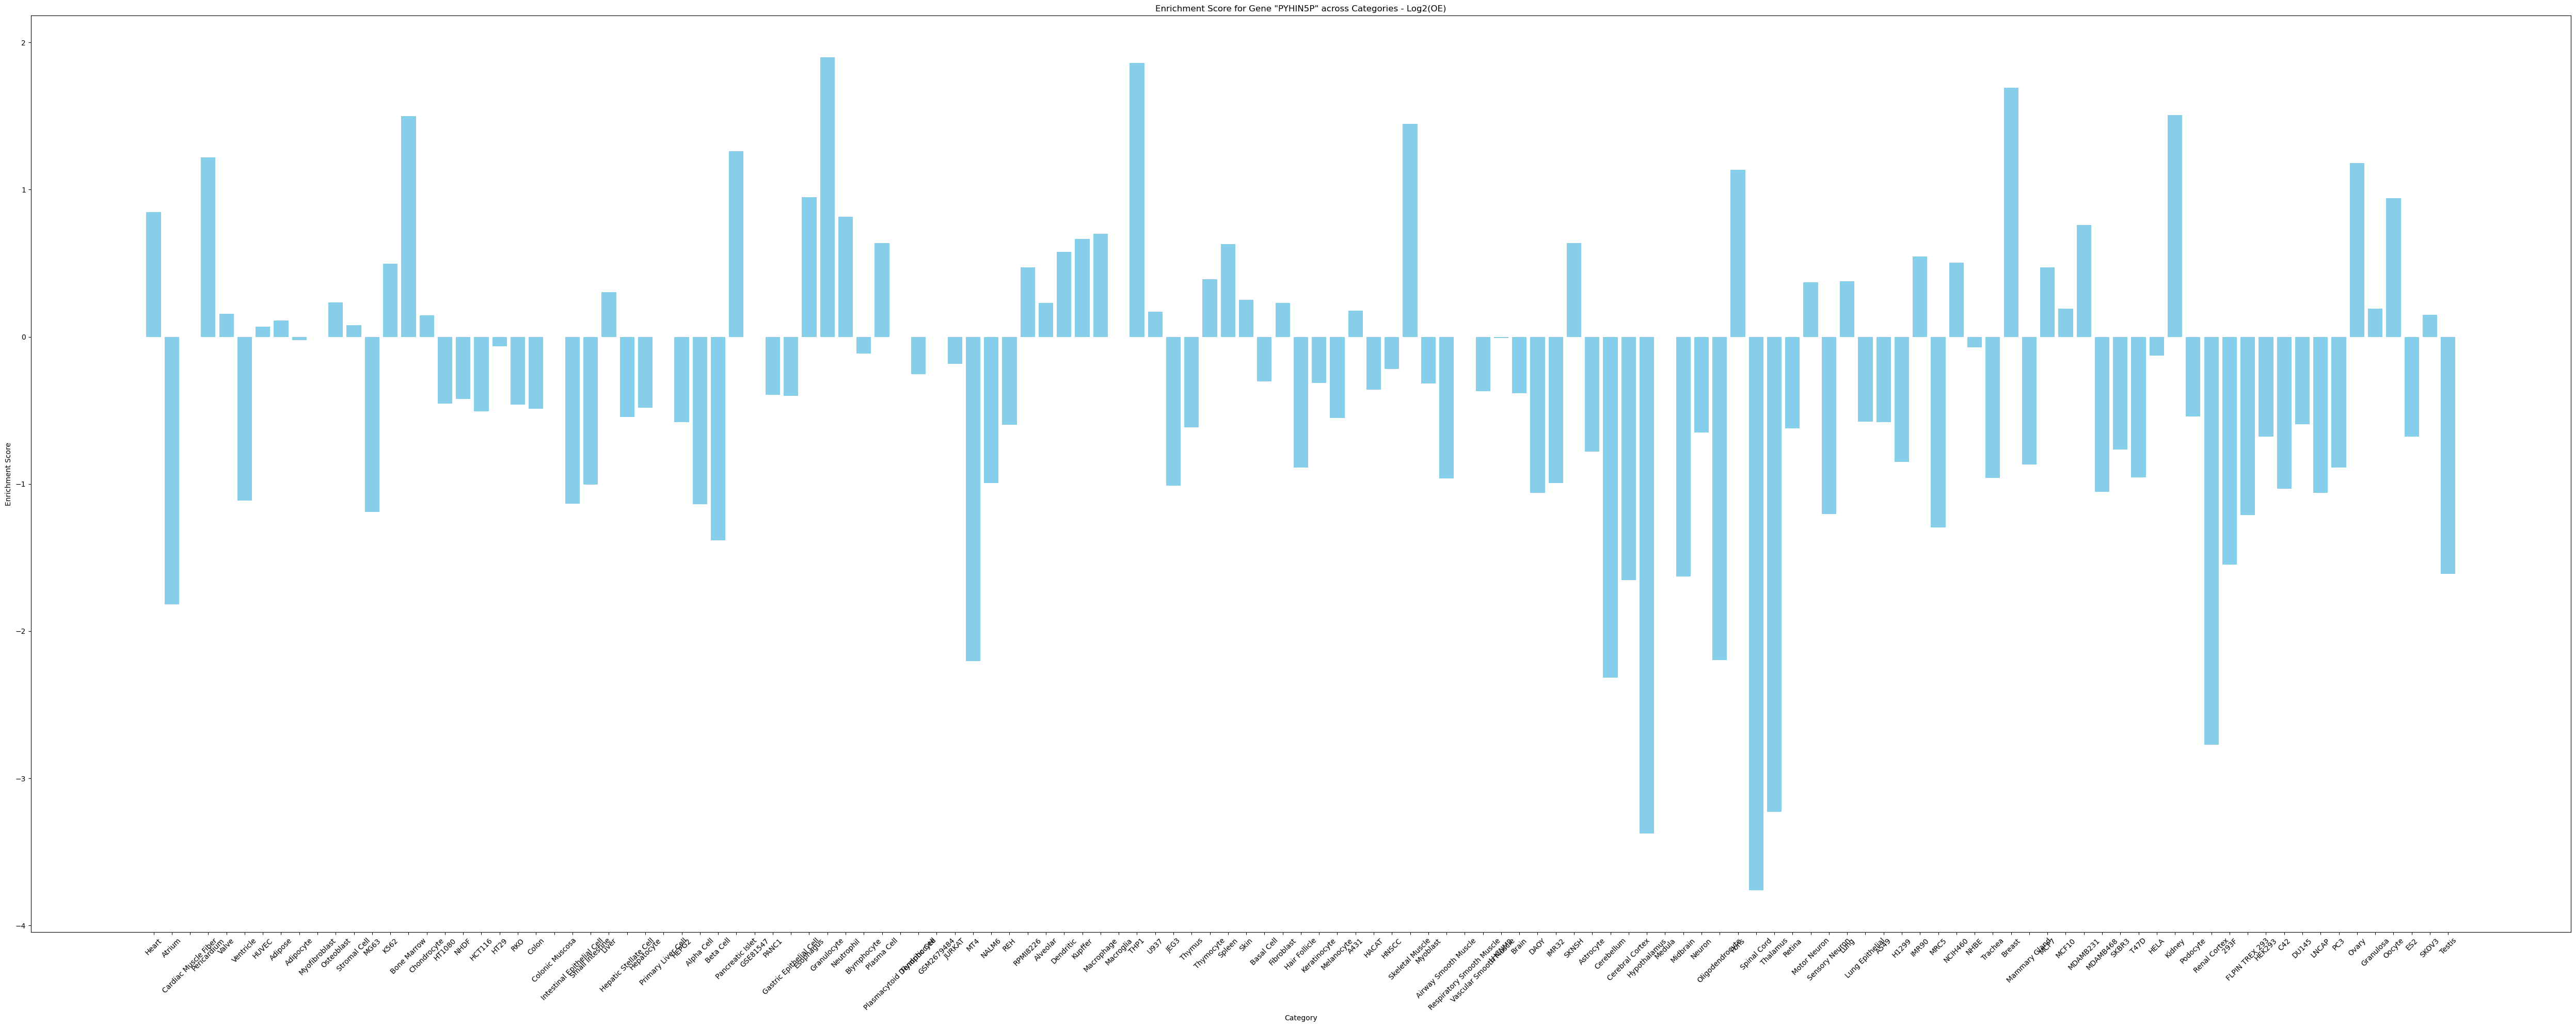

In [13]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'PYHIN5P'

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(50, 20))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories - Log2(OE)'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


---
# High Cat

In [10]:

# Compute row-wise averages while skipping NaN values
row_averages = np.nanmean(high_cat_matrix, axis=1)

# Create new matrix where each value is divided by row average
high_cat_oe_matrix = np.divide(high_cat_matrix, row_averages[:, np.newaxis], 
                       out=np.zeros_like(high_cat_matrix), where=row_averages[:, np.newaxis]!=0)

print("High Cat matrix shape:")
print(high_cat_matrix.shape)
print(high_cat_matrix[0][:5])
print()
print("Average:", row_averages[0])
print()
print("High Cat OE matrix shape:")
print(high_cat_oe_matrix.shape)
print(high_cat_oe_matrix[0][:5])

High Cat matrix shape:
(57447, 9)
[0.03641399 0.12006714 0.4371865  0.13372832 0.09514402]

Average: 0.12443487557940484

High Cat OE matrix shape:
(57447, 9)
[0.29263489 0.96489946 3.51337598 1.07468517 0.76460899]


---
# Save OE Matrix

In [11]:
high_cat_log2_oe_matrix = np.log2(high_cat_oe_matrix)

# Open the HDF5 file in read/write mode
with h5py.File(filename, "a") as file:
    # Access the "data" group
    group = file["data"]
    
    # Create and save the dataset
    group.create_dataset("high_tier_oe_matrix_qn", data=high_cat_oe_matrix)
    group.create_dataset("high_tier_log2oe_matrix_qn", data=high_cat_log2_oe_matrix)
    


In [15]:
# from IPython.display import display

# df = pd.DataFrame(high_cat_oe_matrix, index=gene_names)
# df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
# "Immune System", "Integumentary System", "Muscular System", "Nervous System", 
# "Respiratory System", "Urogenital System"]
# display(df)

In [16]:
# loop through each column and get the top 10 highest values and their indexes

df = pd.DataFrame(high_cat_matrix, index=gene_names)
df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
"Immune System", "Integumentary System", "Muscular System", "Nervous System", 
"Respiratory System", "Urogenital System"]

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print('Indexes for Column "{}":'.format(col))
    print(top_10.index)
    print()

Top 10 values in Column "Cardiovascular System":
GAPDH     5.647761
TMSB4X    5.485484
AHNAK     5.433829
RPL41     5.426241
EEF1A1    4.878405
FTH1      4.813606
RPS18     4.804848
TPM1      4.730638
TMSB10    4.587425
RPL13A    4.565091
Name: Cardiovascular System, dtype: float64
Indexes for Column "Cardiovascular System":
Index(['GAPDH', 'TMSB4X', 'AHNAK', 'RPL41', 'EEF1A1', 'FTH1', 'RPS18', 'TPM1',
       'TMSB10', 'RPL13A'],
      dtype='object')

Top 10 values in Column "Connective Tissue":
RPS18     5.857983
RPL41     5.741125
FTL       5.589432
EEF1A1    5.426893
RPL13A    4.826380
RPS12     4.747020
FTH1      4.700924
RPS25     4.661744
RPL11     4.627384
RPL19     4.623405
Name: Connective Tissue, dtype: float64
Indexes for Column "Connective Tissue":
Index(['RPS18', 'RPL41', 'FTL', 'EEF1A1', 'RPL13A', 'RPS12', 'FTH1', 'RPS25',
       'RPL11', 'RPL19'],
      dtype='object')

Top 10 values in Column "Digestive System":
FTL                5.594203
RPL41              5.491354
G

In [17]:
df = pd.DataFrame(high_cat_oe_matrix, index=gene_names)
df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
"Immune System", "Integumentary System", "Muscular System", "Nervous System", 
"Respiratory System", "Urogenital System"]

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print()
    print('Gene descriptions for Column "{}":'.format(col))
    
    for gene in top_10.index:
        index = gene_names.index(gene)
        print(gene_description[index])
    print()


Top 10 values in Column "Cardiovascular System":
MYBPC3             8.470539
ENSG00000236958    8.351298
MYL7               8.236753
ENSG00000286800    8.219700
ENSG00000287891    8.186218
NPPA               8.147898
LINC02502          8.103888
ENSG00000286820    8.073964
TNNI3K             7.764016
ENSG00000286598    7.692011
Name: Cardiovascular System, dtype: float64

Gene descriptions for Column "Cardiovascular System":
myosin binding protein C3
novel transcript
myosin light chain 7
novel transcript
novel transcript
natriuretic peptide A
long intergenic non-protein coding RNA 2502
novel transcript
TNNI3 interacting kinase
novel transcript

Top 10 values in Column "Connective Tissue":
LINC02573          8.243832
ENSG00000287973    8.194014
ENSG00000237311    8.117703
RHAG               8.083788
ABCB10P4           8.006390
HBBP1              7.996683
HBZ                7.980091
GATA1              7.937128
ENSG00000264334    7.889233
LINC01029          7.878699
Name: Connective Tissue

In [18]:
high_cat_log2_oe_matrix = np.log2(high_cat_oe_matrix)
df = pd.DataFrame(high_cat_log2_oe_matrix, index=gene_names)
df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
"Immune System", "Integumentary System", "Muscular System", "Nervous System", 
"Respiratory System", "Urogenital System"]

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print()
    print('Gene descriptions for Column "{}":'.format(col))
    
    for gene in top_10.index:
        index = gene_names.index(gene)
        print(gene_description[index])
    print()


Top 10 values in Column "Cardiovascular System":
MYBPC3             3.082454
ENSG00000236958    3.062000
MYL7               3.042076
ENSG00000286800    3.039086
ENSG00000287891    3.033197
NPPA               3.026428
LINC02502          3.018614
ENSG00000286820    3.013277
TNNI3K             2.956803
ENSG00000286598    2.943361
Name: Cardiovascular System, dtype: float64

Gene descriptions for Column "Cardiovascular System":
myosin binding protein C3
novel transcript
myosin light chain 7
novel transcript
novel transcript
natriuretic peptide A
long intergenic non-protein coding RNA 2502
novel transcript
TNNI3 interacting kinase
novel transcript

Top 10 values in Column "Connective Tissue":
LINC02573          3.043315
ENSG00000287973    3.034570
ENSG00000237311    3.021072
RHAG               3.015031
ABCB10P4           3.001152
HBBP1              2.999402
HBZ                2.996405
GATA1              2.988617
ENSG00000264334    2.979885
LINC01029          2.977957
Name: Connective Tissue

In [19]:
high_cat_abs_log2_oe_matrix = abs(np.log2(high_cat_oe_matrix))
abs_df = pd.DataFrame(high_cat_abs_log2_oe_matrix, index=gene_names)
abs_df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
"Immune System", "Integumentary System", "Muscular System", "Nervous System", 
"Respiratory System", "Urogenital System"]

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 genes in Column "{}":'.format(col))
    for gene in top_10.index:
        index = gene_names.index(gene)
        value = top_10[gene]
        description = gene_description[index]
        print('{} ({}) [{}]'.format(gene,format(value, ".3f"), description))
    print()

Top 10 genes in Column "Cardiovascular System":
MYBPC3 (3.082) [myosin binding protein C3]
ENSG00000236958 (3.062) [novel transcript]
MYL7 (3.042) [myosin light chain 7]
ENSG00000286800 (3.039) [novel transcript]
ENSG00000287891 (3.033) [novel transcript]
NPPA (3.026) [natriuretic peptide A]
LINC02502 (3.019) [long intergenic non-protein coding RNA 2502]
ENSG00000286820 (3.013) [novel transcript]
TNNI3K (2.957) [TNNI3 interacting kinase]
ENSG00000286598 (2.943) [novel transcript]

Top 10 genes in Column "Connective Tissue":
LINC02573 (3.043) [long intergenic non-protein coding RNA 2573]
ENSG00000287973 (3.035) [novel transcript]
ENSG00000237311 (3.021) [novel transcript]
RHAG (3.015) [Rh associated glycoprotein]
ABCB10P4 (3.001) [ABCB10 pseudogene 4]
HBBP1 (2.999) [hemoglobin subunit beta pseudogene 1]
HBZ (2.996) [hemoglobin subunit zeta]
GATA1 (2.989) [GATA binding protein 1]
ENSG00000264334 (2.980) [novel transcript]
LINC01029 (2.978) [long intergenic non-protein coding RNA 1029]

T

---
# Analysis

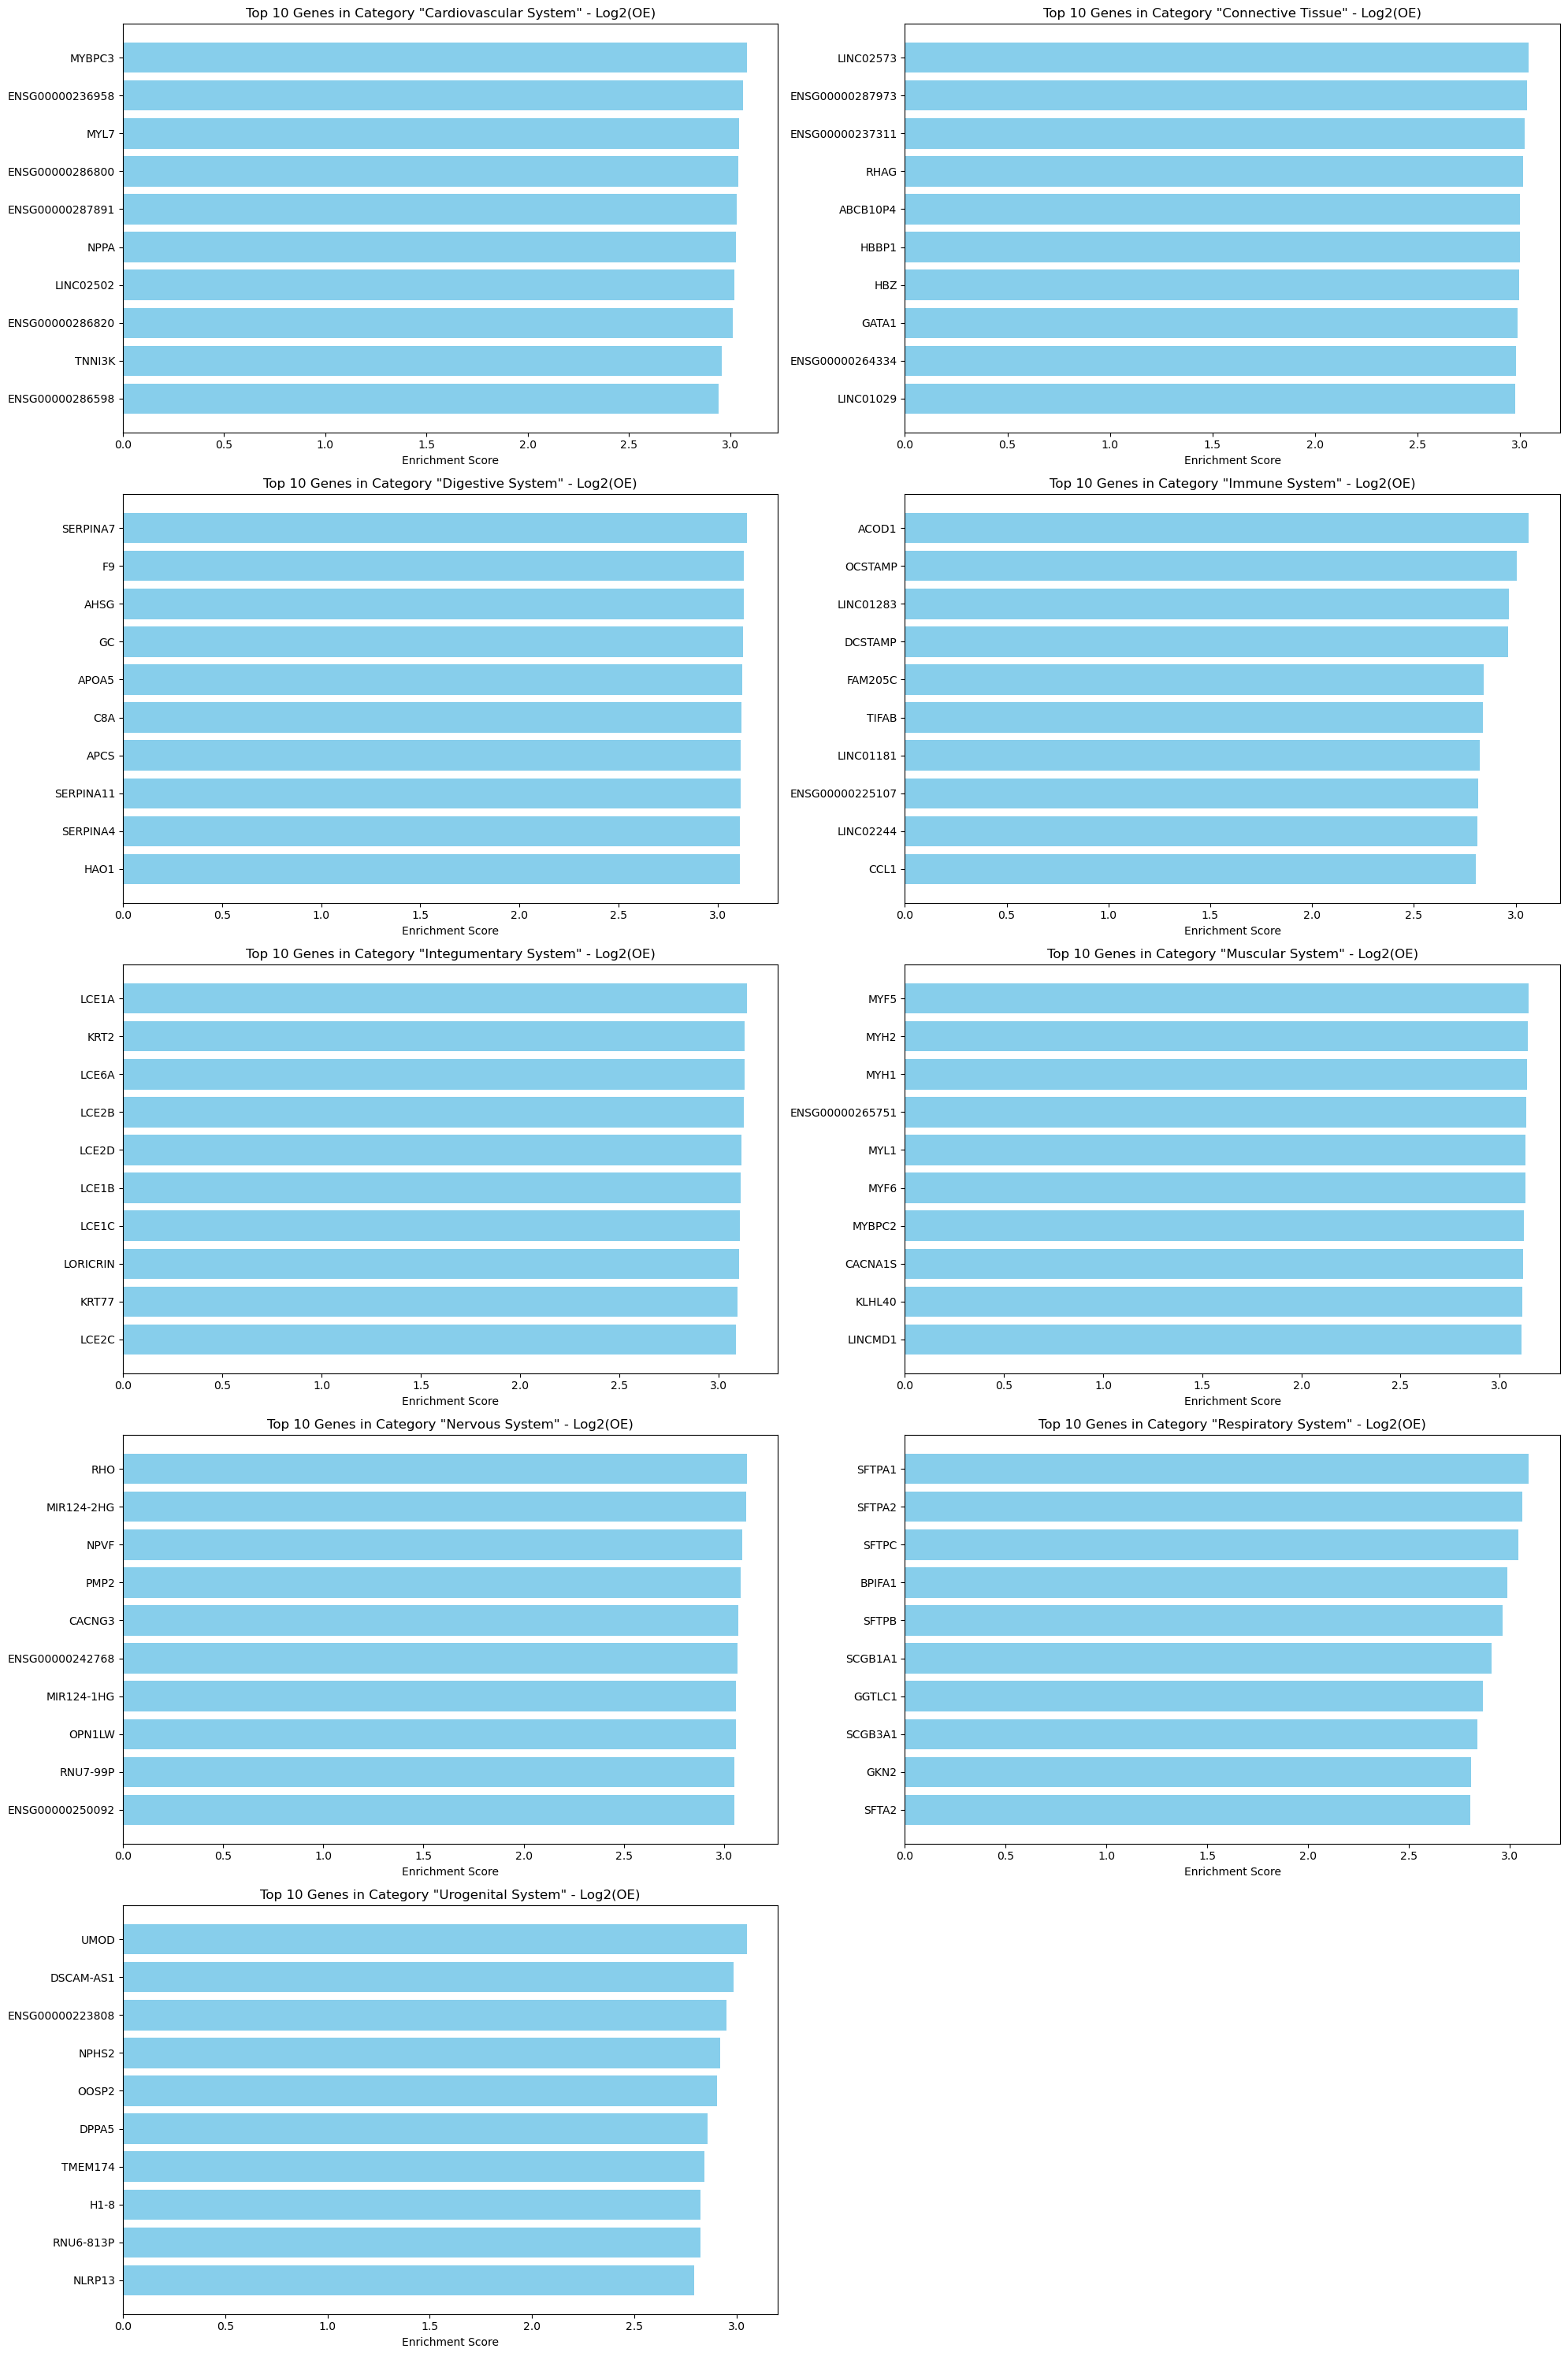

In [20]:
import matplotlib.pyplot as plt

# Set the number of columns and rows for the subplots
num_columns = 2  # Change this value to adjust the number of columns
num_rows = (len(df.columns) + num_columns - 1) // num_columns

# Create the subplots
fig, axes = plt.subplots(num_rows, num_columns, figsize=(20, 30))

# Flatten the axes array to easily access each subplot
axes = axes.flatten()

# Plot top 10 genes for each category
for i, col in enumerate(df.columns):
    top_10 = df[col].nlargest(10)
    genes = [gene_names.index(gene) for gene in top_10.index]
    scores = top_10.values

    # Plot in the respective subplot
    ax = axes[i]
    ax.barh(range(len(genes)), scores, align='center', color='skyblue')
    ax.set_yticks(range(len(genes)))
    ax.set_yticklabels([gene_names[gene] for gene in genes])
    ax.set_xlabel('Enrichment Score')
    ax.set_title('Top 10 Genes in Category "{}" - Log2(OE)'.format(col))
    ax.invert_yaxis()

# Hide any extra subplots
for j in range(len(df.columns), num_columns*num_rows):
    fig.delaxes(axes[j])

# Adjust the layout and spacing
plt.tight_layout()

# Show the plot
plt.show()


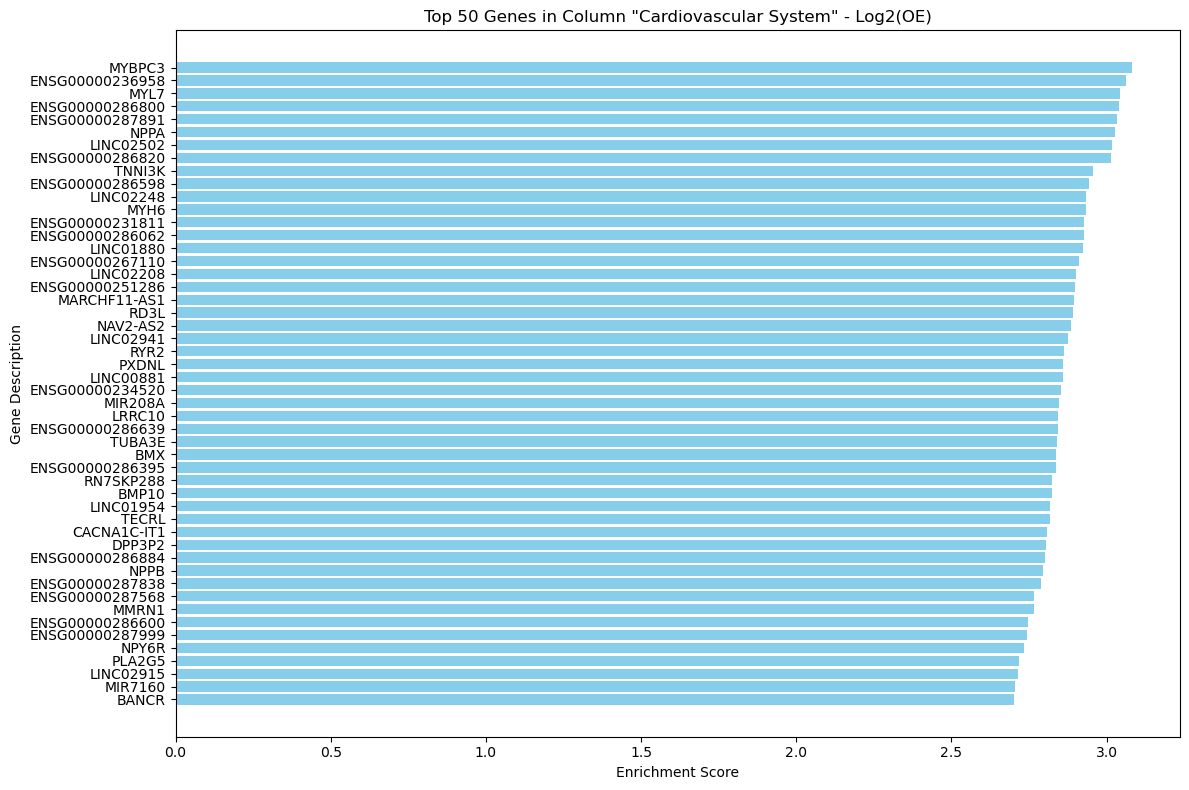

In [21]:
import matplotlib.pyplot as plt

# Select the column for the bar plot
column_name = "Cardiovascular System"

# Get the top 50 scores for the selected column
top_50 = df[column_name].nlargest(50)
genes = [gene_names.index(gene) for gene in top_50.index]
scores = top_50.values

plt.figure(figsize=(12, 8))
plt.barh(range(len(genes)), scores, align='center', color='skyblue')
plt.yticks(range(len(genes)), [gene_names[gene] for gene in genes])
plt.xlabel('Enrichment Score')
plt.ylabel('Gene Description')
plt.title('Top 50 Genes in Column "{}" - Log2(OE)'.format(column_name))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


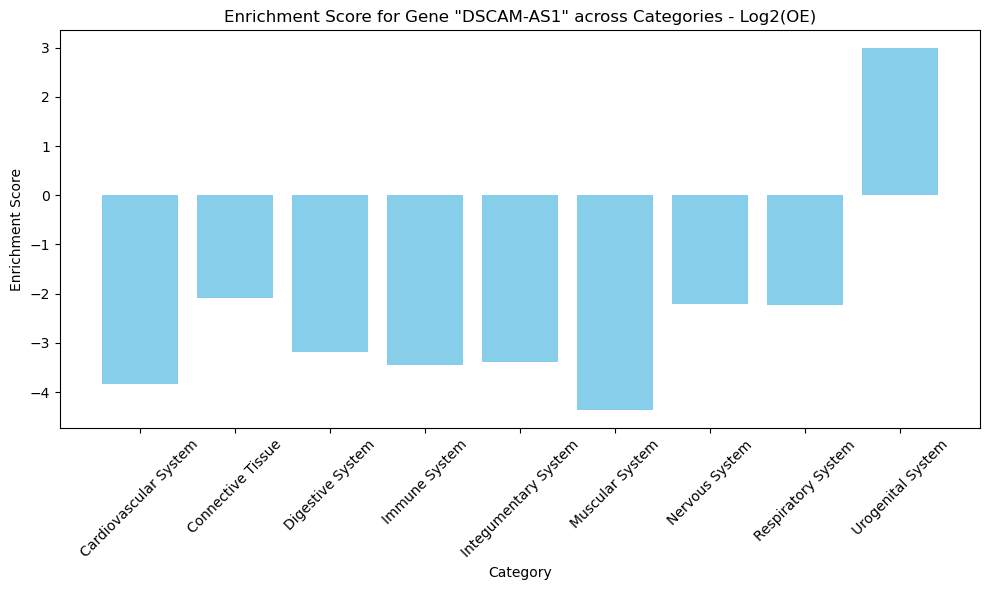

In [22]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'DSCAM-AS1'

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(10, 6))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories - Log2(OE)'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


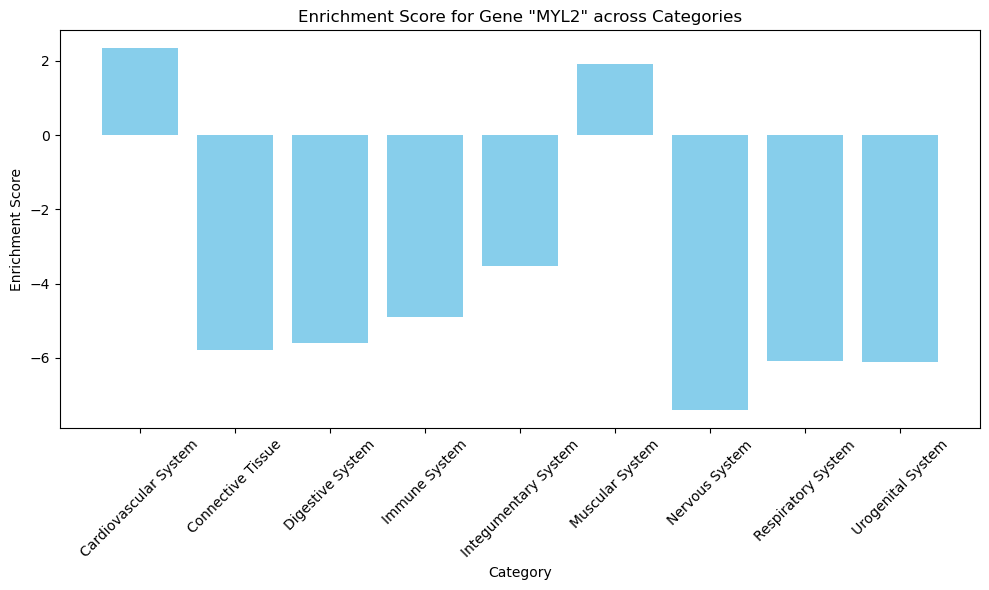

In [23]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'MYL2'

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(10, 6))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [24]:
ENSG00000236958

NameError: name 'ENSG00000236958' is not defined

In [ ]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'DSCAM-AS1' #RHO

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(10, 6))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories - Log2(OE)'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
